In [5]:
import sys

sys.path.append("../src")

from em import GaussianEM
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from utils import cross_validation_split, fix_seed, gerar_dados_sinteticos_queimadas

fix_seed(42)

df = gerar_dados_sinteticos_queimadas(n_samples=1000)
features = [
    "dias_sem_chuva",
    "precipitacao",
    "temperatura_max",
    "umidade_relativa",
    "velocidade_vento",
]
X = df[features].values
y = df["risco_critico"].values


# 1. MLE para Bernoulli
def mle_bernoulli(dados):
    """theta_MLE = k / N"""
    return np.mean(dados)


# 2. MAP para Bernoulli com Prior Beta(alpha, beta)
def map_bernoulli(dados, alpha=2, beta=2):
    """theta_MAP = (k + alpha - 1) / (N + alpha + beta - 2)"""
    k = np.sum(dados)
    n = len(dados)
    return (k + alpha - 1) / (n + alpha + beta - 2)


amostra_bin = (df["umidade_relativa"] <= 45).astype(int).values
theta_mle = mle_bernoulli(amostra_bin)
theta_map = map_bernoulli(amostra_bin, alpha=2, beta=2)

print("=== ESTIMADORES PROBABILÍSTICOS (BERNOULLI) ===")
print(f"Theta (MLE) : {theta_mle:.4f}")
print(f"Theta (MAP com Prior Beta[2,2]) : {theta_map:.4f}")

=== ESTIMADORES PROBABILÍSTICOS (BERNOULLI) ===
Theta (MLE) : 0.4900
Theta (MAP com Prior Beta[2,2]) : 0.4900


In [6]:
class NaiveBayesFromScratch:

    def __init__(self):
        self.classes = None
        self.mean = {}
        self.var = {}
        self.priors = {}

    def fit(self, X, y):
        self.classes = np.unique(y)
        for c in self.classes:
            X_c = X[y == c]
            self.mean[c] = np.mean(X_c, axis=0)
            self.var[c] = np.var(X_c, axis=0) + 1e-6  # Estabilidade numérica
            self.priors[c] = X_c.shape[0] / X.shape[0]

    def _pdf_gaussiana(self, class_idx, x):
        mean = self.mean[class_idx]
        var = self.var[class_idx]
        numerator = np.exp(-((x - mean) ** 2) / (2 * var))
        denominator = np.sqrt(2 * np.pi * var)
        return numerator / denominator

    def predict(self, X):
        y_pred = []
        for x in X:
            posteriors = []
            for c in self.classes:
                prior = np.log(self.priors[c])
                conditional = np.sum(
                    np.log(self._pdf_gaussiana(c, x) + 1e-12)
                )
                posterior = prior + conditional
                posteriors.append(posterior)
            y_pred.append(self.classes[np.argmax(posteriors)])
        return np.array(y_pred)


# Avaliação do Naive Bayes Puro
nb_puro = NaiveBayesFromScratch()
nb_puro.fit(X, y)
acc_nb_puro = accuracy_score(y, nb_puro.predict(X))

print("=== NAIVE BAYES PURO (IMPLEMENTAÇÃO DO ZERO) ===")
print(f"Acurácia no conjunto de treino/teste: {acc_nb_puro * 100:.2f}%")

=== NAIVE BAYES PURO (IMPLEMENTAÇÃO DO ZERO) ===
Acurácia no conjunto de treino/teste: 98.60%


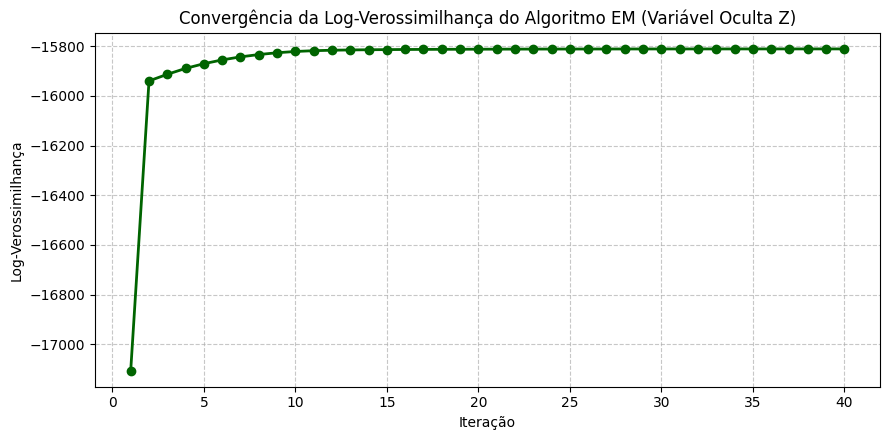

Algoritmo EM convergiu em 40 iterações.


In [7]:
# Instanciar e treinar o algoritmo EM para inferir a variável oculta Z (K=2 componentes)
em_model = GaussianEM(n_components=2, max_iter=40, seed=42)
responsabilidades = em_model.fit(X)
variavel_oculta_Z = np.argmax(responsabilidades, axis=1)

# Plotar a curva de evolução da Log-Verossimilhança
plt.figure(figsize=(9, 4.5))
plt.plot(
    range(1, len(em_model.log_likelihood_history) + 1),
    em_model.log_likelihood_history,
    marker="o",
    color="darkgreen",
    linewidth=2,
)
plt.title("Convergência da Log-Verossimilhança do Algoritmo EM (Variável Oculta Z)")
plt.xlabel("Iteração")
plt.ylabel("Log-Verossimilhança")
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print(
    f"Algoritmo EM convergiu em {len(em_model.log_likelihood_history)} iterações."
)

In [8]:
# Adicionar a variável oculta Z inferida pelo EM como um novo atributo ao modelo (total: 6 atributos)
X_enriquecido = np.column_stack((X, variavel_oculta_Z))

# Avaliação com Validação Cruzada 5-Fold
folds = cross_validation_split(pd.DataFrame(X), y, k=5, seed=42)

acc_puro_list = []
acc_em_list = []

for train_idx, test_idx in folds:
    # Divisão para o modelo puro (5 atributos)
    X_tr, y_tr = X[train_idx], y[train_idx]
    X_te, y_te = X[test_idx], y[test_idx]

    # Divisão para o modelo com EM (6 atributos)
    X_enr_tr = X_enriquecido[train_idx]
    X_enr_te = X_enriquecido[test_idx]

    # Naive Bayes Puro
    nb_p = NaiveBayesFromScratch()
    nb_p.fit(X_tr, y_tr)
    acc_puro_list.append(accuracy_score(y_te, nb_p.predict(X_te)))

    # Naive Bayes + EM (Corrigido: passa X_enr_te na predição)
    nb_em = NaiveBayesFromScratch()
    nb_em.fit(X_enr_tr, y_tr)
    acc_em_list.append(accuracy_score(y_te, nb_em.predict(X_enr_te)))

print("=== COMPARATIVO FINAL DA ETAPA 4 (5-FOLD CROSS-VALIDATION) ===")
print(
    f"Naive Bayes Puro     | Acurácia Média: {np.mean(acc_puro_list)*100:.2f}%"
)
print(
    f"Naive Bayes + EM (Z) | Acurácia Média: {np.mean(acc_em_list)*100:.2f}%"
)

=== COMPARATIVO FINAL DA ETAPA 4 (5-FOLD CROSS-VALIDATION) ===
Naive Bayes Puro     | Acurácia Média: 98.50%
Naive Bayes + EM (Z) | Acurácia Média: 98.50%
